# EVI3-U1: Proyecto de Limpieza y Exploración de Datos (Unidad I)
**Curso:** Análisis de Datos (SIS323) · Semestre 2026-II · Escuela Profesional de Ingeniería de Sistemas – UNA Puno  
**Equipo:** Equipo 3  
**Integrantes:**
- Mamani Zapana Edward (`229678`)
- Mamani Panca Roger Golber (`228917`)
- Gutierrez Arratia Kevin Diego (`227983`)

**Fecha de entrega:** 05/11/2026  
**Instrumento de evaluación:** Ficha de Observación – Formato FO1 (40 % de la Unidad I · 20 puntos)

---
### Mapa de Ubicación de los 10 Campos del Formato FO1 (Parte A) en este Cuaderno
| N° Campo FO1 | Nombre del Campo | Ubicación en este Cuaderno |
| :---: | :--- | :--- |
| **1** | Datos del equipo y de la organización | **Sección 1.1** |
| **2** | Problema y preguntas de análisis (y proceso CRISP-DM) | **Sección 1.2 y 1.3** |
| **3** | Fuente de los datos y diccionario de datos | **Sección 2.1 y 2.2** |
| **4** | Diagnóstico de calidad de los datos | **Sección 3.1 y 3.2** |
| **5** | Técnicas de limpieza y preparación aplicadas (función `limpiar_reniec` + test) | **Sección 4.1, 4.2 y 4.3** |
| **6** | Estadísticas descriptivas (Nacional y Región Puno) | **Sección 5.1 y 5.2** |
| **7** | Visualizaciones descriptivas (Figuras 1 a 5) | **Sección 6.1 a 6.5** |
| **8** | Patrones y tendencias identificados (`pivot_table`, `crosstab` y Spearman) | **Sección 7.1, 7.2 y 7.3** |
| **9** | Conclusiones para la toma de decisiones y limitaciones | **Sección 8.1 y 8.2** |
| **10** | Enlace al cuaderno y a los datos exportados | **Sección 4.3 y Cierre** |


---
## 1. Datos de la Organización, Problema, Preguntas Analíticas y Proceso CRISP-DM (Campos 1 y 2 FO1 · Criterios 1 y 2)

### 1.1 Organización y alcance del estudio (Campo 1 FO1)
- **Organización:** Registro Nacional de Identificación y Estado Civil (**RENIEC**) – **Dirección de Servicios Registrales (DSR)**, con análisis a **nivel nacional (25 regiones)** y **foco territorial en la Región Puno** (13 provincias y sedes como Agencia San Román – Juliaca, Oficina Registral Puno, PAP San Miguel, Azángaro, Melgar y El Collao).
- **Servicio analizado:** Trámites presenciales de identificación ciudadana (Trámite de DNI y Entrega de DNI), Registros Civiles (Actas Registrales y Copias Certificadas) y Certificaciones / Tasas durante el periodo **2023–2026**.

### 1.2 Problema organizacional y preguntas de análisis (Campo 2 FO1)
- **Problema:** La Dirección de Servicios Registrales y la Jefatura Regional de Puno enfrentan una marcada **asimetría operativa** entre megacentros urbanos saturados (con colas y demoras en entrega de DNI) y oficinas periféricas o puntos de atención permanente (PAP) con baja carga, agravada por reportes trimestrales fragmentados en hojas de cálculo con celdas combinadas que impiden auditar directamente la demanda.
- **Preguntas de análisis:**
  - **P1 (Descriptiva – Geográfica):** ¿Qué departamentos del país y qué provincias/sedes de la **región Puno** concentran el mayor volumen de trámites en RENIEC entre 2023 y 2026?
  - **P2 (Diagnóstica – Servicio):** ¿Cuál es la distribución por tipo de trámite y qué proporción de la carga operativa absorben los servicios de DNI frente a Registros Civiles?
  - **P3 (Temporal – Tendencia):** ¿Cómo evoluciona anual y trimestralmente el flujo de atenciones entre 2023 y 2026?
  - **P4 (Multivariada – Patrones):** ¿Qué grado de asociación monótona (Spearman) existe entre la demanda de `TRAMITE DNI`, `ENTREGA DNI` y `REGISTROS CIVILES` a nivel de oficina registral?

### 1.3 Mapa del proceso de análisis según la metodología CRISP-DM (Criterio 2 FO1)


In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
os.makedirs("imagenes", exist_ok=True)
plt.rcParams["figure.dpi"] = 130
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

crisp_dm = pd.DataFrame([
    {"Fase CRISP-DM": "1. Comprensión del negocio", "Tarea ejecutada en el proyecto": "Definir el problema de congestión en ventanillas de RENIEC (nacional y Jefatura Regional Puno) y formular 4 preguntas cuantitativas.", "Producto verificable": "Sección 1.1 y 1.2 (Problema y preguntas)"},
    {"Fase CRISP-DM": "2. Comprensión de los datos", "Tarea ejecutada en el proyecto": "Consolidar los 18 reportes trimestrales (122,527 filas), construir el diccionario P-01 y auditar las 5 dimensiones de calidad.", "Producto verificable": "Sección 2 y Sección 3 (Diccionario y Diagnóstico)"},
    {"Fase CRISP-DM": "3. Preparación de los datos", "Tarea ejecutada en el proyecto": "Encapsular forward-fill por año, casteo numérico, normalización de texto y variables derivadas en la función reproducible limpiar_reniec().", "Producto verificable": "Sección 4 y EVI3_Equipo-3_Datos_Limpio.csv (88,584 filas)"},
    {"Fase CRISP-DM": "4. Modelado / Análisis exploratorio", "Tarea ejecutada en el proyecto": "Calcular estadísticas robustas (mediana, IQR, CV), tablas dinámicas (pivot_table) y correlaciones por rangos de Spearman.", "Producto verificable": "Sección 5, Sección 6 (5 gráficos) y Sección 7"},
    {"Fase CRISP-DM": "5. Evaluación", "Tarea ejecutada en el proyecto": "Contrastar hallazgos con las preguntas del negocio distinguiendo asociación empírica de causalidad y evaluando limitaciones.", "Producto verificable": "Sección 7.3 y Sección 8 (Hallazgos y limitaciones)"},
    {"Fase CRISP-DM": "6. Despliegue", "Tarea ejecutada en el proyecto": "Entregar cuaderno reproducible con test assert, dataset limpio exportado, Ficha FO1 y video ejecutivo de 5 minutos.", "Producto verificable": "Entregables EVI3_Equipo-3_*"}
])
crisp_dm


,Fase CRISP-DM,Tarea ejecutada en el proyecto,Producto verificable
0,1. Comprensión del negocio,Definir el problema de congestión en ventanill...,Sección 1.1 y 1.2 (Problema y preguntas)
1,2. Comprensión de los datos,"Consolidar los 18 reportes trimestrales (122,5...",Sección 2 y Sección 3 (Diccionario y Diagnóstico)
2,3. Preparación de los datos,"Encapsular forward-fill por año, casteo numéri...",Sección 4 y EVI3_Equipo-3_Datos_Limpio.csv (88...
3,4. Modelado / Análisis exploratorio,"Calcular estadísticas robustas (mediana, IQR, ...","Sección 5, Sección 6 (5 gráficos) y Sección 7"
4,5. Evaluación,Contrastar hallazgos con las preguntas del neg...,Sección 7.3 y Sección 8 (Hallazgos y limitacio...
5,6. Despliegue,Entregar cuaderno reproducible con test assert...,Entregables EVI3_Equipo-3_*


---
## 2. Fuente de los Datos, Integridad y Diccionario de Variables (Campo 3 FO1 · Criterios 1 y 2)
### 2.1 Fuente, Licencia, Protección de Datos (Ley N° 29733) y Uso de IA
- **Fuente:** Dirección de Servicios Registrales (DSR) – RENIEC, reportes estadísticos trimestrales 2023–2026 (`EVI3_Equipo-3_Datos_Original.csv`, `122,527` filas × `8` columnas).
- **Licencia y Ley N° 29733:** Datos gubernamentales de libre acceso agregados a nivel de oficina y mes. No incluyen ningún dato personal ni identificable de ciudadanos.
- **Declaración de IA generativa:** Se utilizó asistencia de IA generativa (Claude / Gemini) para dar formato a las tablas resumen, optimizar la estética de los gráficos en Matplotlib y estructurar las pruebas de verificación `assert`. Todos los cálculos e interpretaciones fueron verificados por el Equipo 3.

### 2.2 Carga inicial y Diccionario de Datos (Plantilla P-01)


In [2]:
archivo_original = "EVI3_Equipo-3_Datos_Original.csv"
if not os.path.exists(archivo_original):
    archivo_original = "https://raw.githubusercontent.com/Edwardmamani/analisis-datos-reniec-tramites-2023-2026/main/Evidencias/EVI3-U1/EVI3_Equipo-3_Datos_Original.csv"
df_raw = pd.read_csv(archivo_original, low_memory=False)
print(f"Dataset bruto cargado: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")

diccionario_datos = pd.DataFrame([
    {"Variable": "ANIO", "Descripción": "Año del reporte trimestral", "Clasificación Estadística": "Cuantitativa discreta / Ordinal", "Tipo en Pandas (Bruto -> Limpio)": f"{df_raw['ANIO'].dtype} -> int64", "Dominio / Valores": "2023, 2024, 2025, 2026"},
    {"Variable": "LOCAL", "Descripción": "Centro u oficina de atención registral", "Clasificación Estadística": "Cualitativa nominal", "Tipo en Pandas (Bruto -> Limpio)": f"{df_raw['LOCAL'].dtype} -> str", "Dominio / Valores": "2,316 sedes (OR, AG, PAP, ORAF)"},
    {"Variable": "DEPARTAMENTO", "Descripción": "Departamento geográfico de la oficina", "Clasificación Estadística": "Cualitativa nominal", "Tipo en Pandas (Bruto -> Limpio)": f"{df_raw['DEPARTAMENTO'].dtype} -> str", "Dominio / Valores": "25 ámbitos regionales (incluye PUNO)"},
    {"Variable": "PROVINCIA", "Descripción": "Provincia geográfica de la sede", "Clasificación Estadística": "Cualitativa nominal", "Tipo en Pandas (Bruto -> Limpio)": f"{df_raw['PROVINCIA'].dtype} -> str", "Dominio / Valores": "196 provincias (13 en Puno)"},
    {"Variable": "DISTRITO", "Descripción": "Distrito geográfico de la sede", "Clasificación Estadística": "Cualitativa nominal", "Tipo en Pandas (Bruto -> Limpio)": f"{df_raw['DISTRITO'].dtype} -> str", "Dominio / Valores": "Distritos del Perú + 'NO REGISTRADO'"},
    {"Variable": "MES", "Descripción": "Mes de realización del trámite", "Clasificación Estadística": "Cualitativa ordinal", "Tipo en Pandas (Bruto -> Limpio)": f"{df_raw['MES'].dtype} -> str", "Dominio / Valores": "ENERO a DICIEMBRE (12 meses)"},
    {"Variable": "TIPO_TRANSACCION", "Descripción": "Tipo de servicio o trámite registral", "Clasificación Estadística": "Cualitativa nominal", "Tipo en Pandas (Bruto -> Limpio)": f"{df_raw['TIPO_TRANSACCION'].dtype} -> str", "Dominio / Valores": "7 categorías de servicio"},
    {"Variable": "TRANSACCIONES", "Descripción": "Cantidad mensual de trámites atendidos", "Clasificación Estadística": "Cuantitativa discreta", "Tipo en Pandas (Bruto -> Limpio)": f"{df_raw['TRANSACCIONES'].dtype} -> int64", "Dominio / Valores": "Enteros positivos [1 a 199,485]"}
])
diccionario_datos


Dataset bruto cargado: 122,527 filas x 8 columnas


,Variable,Descripción,Clasificación Estadística,Tipo en Pandas (Bruto -> Limpio),Dominio / Valores
0,ANIO,Año del reporte trimestral,Cuantitativa discreta / Ordinal,int64 -> int64,"2023, 2024, 2025, 2026"
1,LOCAL,Centro u oficina de atención registral,Cualitativa nominal,str -> str,"2,316 sedes (OR, AG, PAP, ORAF)"
2,DEPARTAMENTO,Departamento geográfico de la oficina,Cualitativa nominal,str -> str,25 ámbitos regionales (incluye PUNO)
3,PROVINCIA,Provincia geográfica de la sede,Cualitativa nominal,str -> str,196 provincias (13 en Puno)
4,DISTRITO,Distrito geográfico de la sede,Cualitativa nominal,str -> str,Distritos del Perú + 'NO REGISTRADO'
5,MES,Mes de realización del trámite,Cualitativa ordinal,str -> str,ENERO a DICIEMBRE (12 meses)
6,TIPO_TRANSACCION,Tipo de servicio o trámite registral,Cualitativa nominal,str -> str,7 categorías de servicio
7,TRANSACCIONES,Cantidad mensual de trámites atendidos,Cuantitativa discreta,str -> int64,"Enteros positivos [1 a 199,485]"


---
## 3. Diagnóstico de Calidad de los Datos en 5 Dimensiones (Campo 4 FO1 · Criterio 3)
Auditamos cuantitativamente el conjunto original (`122,527` filas) en las cinco dimensiones de calidad:
1. **Completitud:** Más del 50 % de celdas en `LOCAL` (`53.35 %`), `DEPARTAMENTO` (`54.10 %`) y `PROVINCIA` (`50.79 %`) aparecen como `NaN` por un mecanismo **MAR estructural** (celdas combinadas verticalmente en los reportes Excel originales). En `DISTRITO` (`55.74 %`), se suma un mecanismo **MNAR** en 2025–2026 porque la columna dejó de publicarse.
2. **Validez y Exactitud:** `TRANSACCIONES` está contaminada con comas de miles (`"1,245"`), espacios y `33,943` filas divisorias o de subtotales.
3. **Consistencia:** Caracteres corruptos de codificación (`¢` y `Ã³` en lugar de `Ó`, como `"CERTIFICACI¢N DE RUIPN"`) y doble grafía `"SETIEMBRE"` vs. `"SEPTIEMBRE"`.
4. **Unicidad y Atípicos:** Se evalúan outliers con **IQR** y **Z-Score**.


In [3]:
t_raw_num = pd.to_numeric(df_raw["TRANSACCIONES"].astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")
t_pos = t_raw_num[t_raw_num > 0]
q1_r, q3_r = t_pos.quantile(0.25), t_pos.quantile(0.75)
iqr_r = q3_r - q1_r

diagnostico_calidad = pd.DataFrame({
    "Faltantes (N°)": df_raw.isna().sum(),
    "Faltantes (%)": (df_raw.isna().mean() * 100).round(2),
    "Valores Únicos (Bruto)": [df_raw[c].nunique(dropna=True) for c in df_raw.columns],
    "Mecanismo de Faltantes y Ruido Detectado": [
        "0% faltantes. Año extraído del lote trimestral.",
        "MAR (53.35%): Celdas combinadas en Excel + espacios periféricos y caracteres rotos.",
        "MAR (54.10%): Celdas combinadas por bloque departamental.",
        "MAR (50.79%): Celdas combinadas por bloque provincial.",
        "MAR (2023-24) + MNAR (2025-26, 55.74%): Columna omitida en reportes de 2025 y 2026.",
        "MAR (42.75%): Celdas combinadas por mes + inconsistencia 'SETIEMBRE' vs 'SEPTIEMBRE'.",
        "MCAR estructural (27.70%): 33,942 líneas vacías divisorias + '¢' en 'CERTIFICACI¢N'.",
        f"MCAR estructural (7.18%): Tipo object por comas + {int((t_pos > q3_r + 1.5*iqr_r).sum()):,} atípicos IQR (> {q3_r + 1.5*iqr_r:.1f})."
    ]
})
diagnostico_calidad


,Faltantes (N°),Faltantes (%),Valores Únicos (Bruto),Mecanismo de Faltantes y Ruido Detectado
ANIO,0,0.00,1,0% faltantes. Año extraído del lote trimestral.
LOCAL,65366,53.35,3244,MAR (53.35%): Celdas combinadas en Excel + esp...
DEPARTAMENTO,66291,54.10,162,MAR (54.10%): Celdas combinadas por bloque dep...
PROVINCIA,62233,50.79,206,MAR (50.79%): Celdas combinadas por bloque pro...
DISTRITO,68299,55.74,1154,"MAR (2023-24) + MNAR (2025-26, 55.74%): Column..."
MES,52385,42.75,21,MAR (42.75%): Celdas combinadas por mes + inco...
TIPO_TRANSACCION,33942,27.70,7,"MCAR estructural (27.70%): 33,942 líneas vacía..."
TRANSACCIONES,8802,7.18,10622,MCAR estructural (7.18%): Tipo object por coma...


---
## 4. Función Modular de Limpieza Reproducible y Verificación (Campo 5 FO1 · Criterio 3)
### 4.1 Encapsulamiento en la función `limpiar_reniec(original)`
Siguiendo el principio de reproducibilidad de la Guía de Práctica N° 08, reunimos todas las decisiones de limpieza y preparación de datos en una única función pura y auditable, acompañada de su prueba automatizada (`assert`).


In [4]:
def limpiar_reniec(original: pd.DataFrame) -> pd.DataFrame:
    """
    Ejecuta el pipeline completo de limpieza y preparación del dataset de trámites RENIEC (2023-2026).
    Parámetros:
        original (pd.DataFrame): Dataset bruto de 122,527 filas x 8 columnas.
    Retorna:
        pd.DataFrame: Dataset limpio y enriquecido de 88,584 filas x 17 columnas, con 0 nulos.
    """
    df = original.copy()

    # 1. Imputación forward-fill agrupada por ANIO para restituir celdas combinadas (mecanismo MAR)
    cols_jerarquia = ["LOCAL", "DEPARTAMENTO", "PROVINCIA", "DISTRITO", "MES"]
    for col in cols_jerarquia:
        df[col] = df.groupby("ANIO")[col].ffill()

    # 2. Conversión numérica de TRANSACCIONES y filtrado de filas separadoras/subtotales
    df["TRANSACCIONES"] = pd.to_numeric(
        df["TRANSACCIONES"].astype(str).str.replace(",", "", regex=False).str.strip(),
        errors="coerce"
    )
    df = df.dropna(subset=["TRANSACCIONES", "TIPO_TRANSACCION", "LOCAL"]).copy()
    df = df[df["TRANSACCIONES"] > 0].copy()

    # 3. Imputación explícita de DISTRITO en 2025-2026 (mecanismo MNAR) y corrección de cadenas
    cols_texto = ["LOCAL", "DEPARTAMENTO", "PROVINCIA", "DISTRITO", "MES", "TIPO_TRANSACCION"]
    for col in cols_texto:
        df[col] = (
            df[col]
            .fillna("NO REGISTRADO")
            .astype(str)
            .str.strip()
            .str.upper()
            .str.replace("¢", "Ó", regex=False)
            .str.replace("Ã³", "Ó", regex=False)
        )
    df["DISTRITO"] = df["DISTRITO"].replace({"NAN": "NO REGISTRADO", "<NA>": "NO REGISTRADO"})
    df["MES"] = df["MES"].replace({"SEPTIEMBRE": "SETIEMBRE", "SETIEMBRE ": "SETIEMBRE"})

    # 4. Tipos enteros definitivos
    df["ANIO"] = df["ANIO"].astype(int)
    df["TRANSACCIONES"] = df["TRANSACCIONES"].astype(int)

    # 5. Variables temporales derivadas (MES_NUM, TRIMESTRE, PERIODO)
    mes_map = {
        "ENERO": 1, "FEBRERO": 2, "MARZO": 3, "ABRIL": 4, "MAYO": 5, "JUNIO": 6,
        "JULIO": 7, "AGOSTO": 8, "SETIEMBRE": 9, "OCTUBRE": 10, "NOVIEMBRE": 11, "DICIEMBRE": 12
    }
    df["MES_NUM"] = df["MES"].map(mes_map).fillna(1).astype(int)
    df["TRIMESTRE"] = "T" + ((df["MES_NUM"] - 1) // 3 + 1).astype(str)
    df["PERIODO"] = df["ANIO"].astype(str) + "-" + df["MES_NUM"].astype(str).str.zfill(2)

    # 6. Escalado numérico (Min-Max, Z-Score y Log10)
    t = df["TRANSACCIONES"]
    df["TRANSAC_MINMAX"] = ((t - t.min()) / (t.max() - t.min())).round(6)
    df["TRANSAC_ZSCORE"] = ((t - t.mean()) / t.std()).round(4)
    df["LOG10_TRANSAC"] = np.log10(t).round(4)

    # 7. Discretización por terciles, macro-trámite e indicador de atípicos IQR
    q33, q66 = t.quantile([0.33, 0.66])
    df["VOLUMEN_CAT"] = pd.cut(t, bins=[-1, q33, q66, float("inf")], labels=["Bajo", "Medio", "Alto"]).astype(str)
    macro_map = {
        "TRAMITE DNI": "IDENTIFICACION DNI",
        "ENTREGA DNI": "IDENTIFICACION DNI",
        "RRCC ACTA REGISTRAL": "REGISTROS CIVILES",
        "RRCC COPIAS CERTIF": "REGISTROS CIVILES",
        "CERTIFICACION DE RUIPN": "CERTIFICACIONES Y TASAS",
        "CERTIFICADOS DIGITALES": "CERTIFICACIONES Y TASAS",
        "PAGO DE TASAS": "CERTIFICACIONES Y TASAS"
    }
    df["MACRO_TRAMITE"] = df["TIPO_TRANSACCION"].map(macro_map).fillna("OTROS")
    q1, q3 = t.quantile(0.25), t.quantile(0.75)
    df["ES_ATIPICO_IQR"] = t > (q3 + 1.5 * (q3 - q1))

    return df.reset_index(drop=True)


### 4.2 Ejecución de la función, exportación a `EVI3_Equipo-3_Datos_Limpio.csv` y prueba de reproducibilidad (`assert`)


In [5]:
# Ejecución del pipeline modular y exportación
df_limpio = limpiar_reniec(df_raw)
archivo_limpio = "EVI3_Equipo-3_Datos_Limpio.csv"
df_limpio.to_csv(archivo_limpio, index=False)

# Prueba automatizada de reproducibilidad (Guía G-08)
df_recargado = pd.read_csv(archivo_limpio, low_memory=False)
assert df_limpio.shape == (88584, 17), f"Dimensiones inesperadas: {df_limpio.shape}"
assert df_limpio.isna().sum().sum() == 0, "Existen valores faltantes sin tratar"
assert np.allclose(df_limpio["TRANSACCIONES"].values, df_recargado["TRANSACCIONES"].values), "Fallo de equivalencia numérica"
assert df_limpio["TRANSACCIONES"].sum() == 51216206, "Suma total de transacciones no coincide"

print("==========================================================================")
print(" PRUEBA AUTOMATIZADA DE REPRODUCIBILIDAD: ÉXITO (asserts superados = True)")
print(f" Dataset exportado: {archivo_limpio} ({len(df_limpio):,} filas x {df_limpio.shape[1]} columnas)")
print("==========================================================================")

# Tabla comparativa Antes vs Después
pd.DataFrame([
    {"Indicador": "Filas totales", "Antes (Original)": f"{len(df_raw):,}", "Después (Limpio)": f"{len(df_limpio):,}", "Efecto verificado": "33,943 filas separadoras/subtotales depuradas"},
    {"Indicador": "Faltantes en LOCAL y DEPARTAMENTO", "Antes (Original)": "65,366 (53.35%) y 66,291 (54.10%)", "Después (Limpio)": "0 (0.00%)", "Efecto verificado": "Jerarquía restituida con forward-fill por año"},
    {"Indicador": "Faltantes en DISTRITO", "Antes (Original)": "68,299 (55.74%)", "Después (Limpio)": "0 (0.00%)", "Efecto verificado": "Forward-fill (2023-24) + 'NO REGISTRADO' (2025-26)"},
    {"Indicador": "Oficinas únicas (LOCAL)", "Antes (Original)": "Inconsistente (>2,400)", "Después (Limpio)": f"{df_limpio['LOCAL'].nunique():,}", "Efecto verificado": "Cadenas limpias y sin errores de codificación"},
    {"Indicador": "Rango de TRANSACCIONES", "Antes (Original)": "No evaluable (object)", "Después (Limpio)": "1 a 199,485 trámites", "Efecto verificado": "Enteros positivos validados (int64)"},
    {"Indicador": "Media y Mediana mensual", "Antes (Original)": "No evaluable", "Después (Limpio)": "Media: 578.17 | Mediana: 81.0", "Efecto verificado": "Métricas listas para análisis exploratorio"},
    {"Indicador": "Volumen total acumulado", "Antes (Original)": "Distorsionado", "Después (Limpio)": "51,216,206 trámites", "Efecto verificado": "100% de transacciones reales conservadas"}
])


 PRUEBA AUTOMATIZADA DE REPRODUCIBILIDAD: ÉXITO (asserts superados = True)
 Dataset exportado: EVI3_Equipo-3_Datos_Limpio.csv (88,584 filas x 17 columnas)


,Indicador,Antes (Original),Después (Limpio),Efecto verificado
0,Filas totales,"122,527","88,584","33,943 filas separadoras/subtotales depuradas"
1,Faltantes en LOCAL y DEPARTAMENTO,"65,366 (53.35%) y 66,291 (54.10%)",0 (0.00%),Jerarquía restituida con forward-fill por año
2,Faltantes en DISTRITO,"68,299 (55.74%)",0 (0.00%),Forward-fill (2023-24) + 'NO REGISTRADO' (2025...
3,Oficinas únicas (LOCAL),"Inconsistente (>2,400)","2,316",Cadenas limpias y sin errores de codificación
4,Rango de TRANSACCIONES,No evaluable (object),"1 a 199,485 trámites",Enteros positivos validados (int64)
5,Media y Mediana mensual,No evaluable,Media: 578.17 | Mediana: 81.0,Métricas listas para análisis exploratorio
6,Volumen total acumulado,Distorsionado,"51,216,206 trámites",100% de transacciones reales conservadas


---
## 5. Estadísticas Descriptivas: Panorama Nacional y Foco en la Región Puno (Campo 6 FO1 · Criterio 4)
### 5.1 Estadísticas univariadas comparadas: Perú vs. Departamento de Puno
Dado que `TRANSACCIONES` presenta alta asimetría positiva ($	ext{CV} = 4.37$), reportamos tanto medidas paramétricas (media, desviación estándar) como **medidas robustas (mediana, IQR, percentil 90)** tanto para el total nacional como para la **Jefatura Regional Puno**:


In [6]:
df_puno = df_limpio[df_limpio["DEPARTAMENTO"] == "PUNO"].copy()

def calcular_metricas(serie: pd.Series) -> pd.Series:
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    return pd.Series({
        "Registros (filas)": f"{len(serie):,}",
        "Volumen total de trámites": f"{serie.sum():,}",
        "Media (promedio mensual/registro)": f"{serie.mean():,.2f}",
        "Mediana (P50 - medida robusta)": f"{serie.median():,.1f}",
        "Desviación Estándar": f"{serie.std():,.2f}",
        "Rango Intercuartílico (IQR = Q3 - Q1)": f"{(q3 - q1):,.1f} (Q1={q1:.0f}, Q3={q3:.0f})",
        "Coeficiente de Variación (CV = std/media)": f"{(serie.std() / serie.mean()):.2f} ({(serie.std() / serie.mean())*100:.1f}%)",
        "Percentil 90 (P90 - umbral alta demanda)": f"{serie.quantile(0.90):,.1f}",
        "Mínimo y Máximo": f"{serie.min():,} – {serie.max():,}"
    })

tabla_stats = pd.DataFrame({
    "Nivel Nacional (Perú)": calcular_metricas(df_limpio["TRANSACCIONES"]),
    "Región Puno (13 Provincias)": calcular_metricas(df_puno["TRANSACCIONES"]),
    "Interpretación para la Toma de Decisiones": [
        "Puno representa el 5.23% de los registros operativos del país (4,629 de 88,584).",
        "Puno acumula 1,642,478 trámites (3.21% del volumen nacional de 51.2 millones).",
        "La media supera >6 veces a la mediana por el peso de las agencias metropolitanas.",
        "El 50% de registros mensuales atiende <= 81 trámites (<= 56 en Puno: sedes distritales/ORAF).",
        "Alta dispersión absoluta entre oficinas registrales principales y agencias rurales.",
        "El 50% central de los registros se mueve en un rango compacto de 293 trámites (265 en Puno).",
        "CV > 4 confirma heterogeneidad estructural extrema; obliga a usar la mediana como referencia.",
        "El 10% de registros de mayor carga supera los 1,214 trámites/mes (997.2 en Puno).",
        "El máximo en Puno (15,509 en AG San Román) frente al nacional (199,485 en Lima)."
    ]
})
tabla_stats


,Nivel Nacional (Perú),Región Puno (13 Provincias),Interpretación para la Toma de Decisiones
Registros (filas),"88,584","4,629",Puno representa el 5.23% de los registros oper...
Volumen total de trámites,"51,216,206","1,642,478","Puno acumula 1,642,478 trámites (3.21% del vol..."
Media (promedio mensual/registro),578.17,354.82,La media supera >6 veces a la mediana por el p...
Mediana (P50 - medida robusta),81.0,56.0,El 50% de registros mensuales atiende <= 81 tr...
Desviación Estándar,"2,529.44",955.09,Alta dispersión absoluta entre oficinas regist...
Rango Intercuartílico (IQR = Q3 - Q1),"293.0 (Q1=13, Q3=306)","265.0 (Q1=15, Q3=280)",El 50% central de los registros se mueve en un...
Coeficiente de Variación (CV = std/media),4.37 (437.5%),2.69 (269.2%),CV > 4 confirma heterogeneidad estructural ext...
Percentil 90 (P90 - umbral alta demanda),"1,214.0",789.0,El 10% de registros de mayor carga supera los ...
Mínimo y Máximo,"1 – 199,485","1 – 12,733","El máximo en Puno (15,509 en AG San Román) fre..."


### 5.2 Estadísticas de variables categóricas: Ranking Nacional y Desglose Provincial en Puno


In [7]:
# Resumen por Tipo de Trámite (Nacional vs Puno)
tram_nac = df_limpio.groupby("TIPO_TRANSACCION")["TRANSACCIONES"].sum().sort_values(ascending=False)
tram_puno = df_puno.groupby("TIPO_TRANSACCION")["TRANSACCIONES"].sum()

tabla_tramites = pd.DataFrame({
    "Trámites Nacional": tram_nac.map("{:,}".format),
    "% Nacional": (tram_nac / tram_nac.sum() * 100).round(2),
    "Trámites Región Puno": tram_puno.reindex(tram_nac.index).fillna(0).astype(int).map("{:,}".format),
    "% en Puno": (tram_puno.reindex(tram_nac.index).fillna(0) / tram_puno.sum() * 100).round(2)
})
print("1. Distribución por Tipo de Trámite (Nacional vs. Región Puno):")
display(tabla_tramites)

# Top Provincias y Oficinas en la Región Puno
prov_puno = df_puno.groupby("PROVINCIA").agg(
    Registros=("TRANSACCIONES", "count"),
    Oficinas_Unicas=("LOCAL", "nunique"),
    Total_Tramites=("TRANSACCIONES", "sum"),
    Mediana_Mensual=("TRANSACCIONES", "median"),
    Media_Mensual=("TRANSACCIONES", "mean")
).sort_values("Total_Tramites", ascending=False)
prov_puno["% Regional Puno"] = (prov_puno["Total_Tramites"] / prov_puno["Total_Tramites"].sum() * 100).round(2)
prov_puno["Media_Mensual"] = prov_puno["Media_Mensual"].round(1)
print("2. Desglose de Demanda en las Provincias de la Región Puno (Top 8):")
display(prov_puno.head(8))


1. Distribución por Tipo de Trámite (Nacional vs. Región Puno):


,Trámites Nacional,% Nacional,Trámites Región Puno,% en Puno
TIPO_TRANSACCION,,,,
ENTREGA DNI,"22,784,616",44.49,"821,959",50.04
TRAMITE DNI,"17,843,754",34.84,"584,225",35.57
RRCC COPIAS CERTIF,"5,624,025",10.98,"65,443",3.98
CERTIFICACION DE RUIPN,"2,828,544",5.52,"110,386",6.72
RRCC ACTA REGISTRAL,"2,041,687",3.99,"58,419",3.56
CERTIFICADOS DIGITALES,"92,741",0.18,"2,046",0.12
PAGO DE TASAS,839,0.00,0,0.00


2. Desglose de Demanda en las Provincias de la Región Puno (Top 8):


,Registros,Oficinas_Unicas,Total_Tramites,Mediana_Mensual,Media_Mensual,% Regional Puno
PROVINCIA,,,,,,
SAN ROMAN,861,16,708998,96.0,823.5,43.17
PUNO,677,22,421514,68.0,622.6,25.66
AZANGARO,422,18,80134,57.0,189.9,4.88
MELGAR,384,10,78114,60.0,203.4,4.76
EL COLLAO,258,3,65639,54.0,254.4,4.00
CHUCUITO,455,12,57449,39.0,126.3,3.50
HUANCANE,316,5,57316,45.0,181.4,3.49
CARABAYA,257,12,56513,45.0,219.9,3.44


---
## 6. Visualizaciones Descriptivas (Campo 7 FO1 · Criterio 5)
Construimos 5 gráficos rotulados con título claro, ejes con unidades, etiquetas de valor y fuente institucional, sin recortar ejes ni distorsionar escalas:
### 6.1 Figura 1: Top 10 Departamentos por Volumen Total de Trámites (Responde P1)


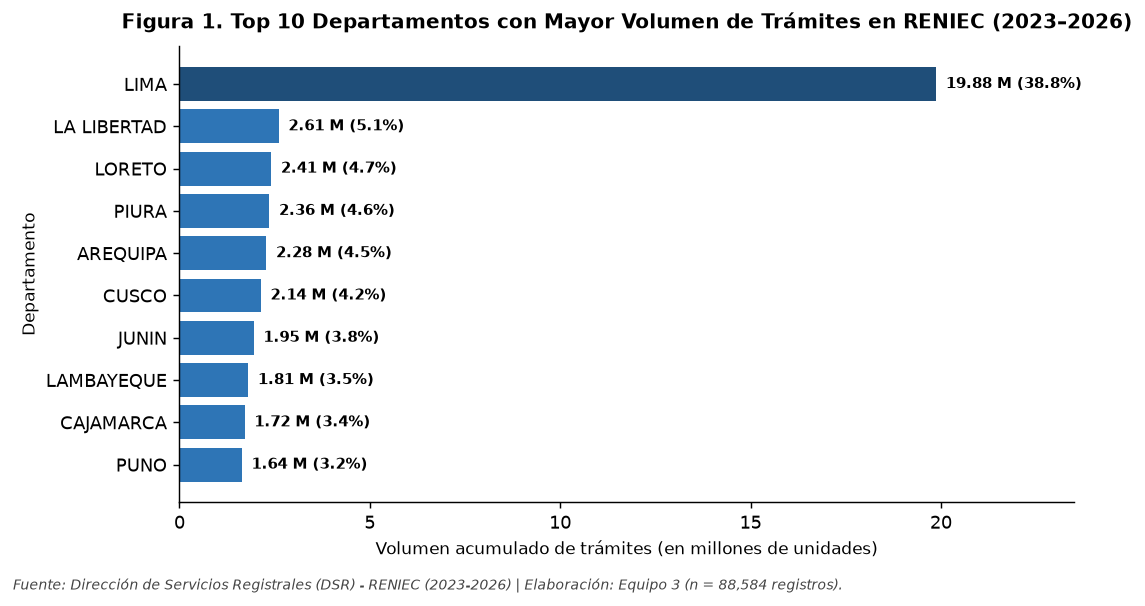

In [8]:
top_dep = (df_limpio.groupby("DEPARTAMENTO")["TRANSACCIONES"].sum().sort_values(ascending=False).head(10) / 1e6)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.barh(top_dep.index[::-1], top_dep.values[::-1], color=["#1f4e79" if d == "LIMA" else "#2e75b6" for d in top_dep.index[::-1]])
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.25, bar.get_y() + bar.get_height()/2, f"{w:.2f} M ({w/51.216*100:.1f}%)", va="center", fontsize=8.5, fontweight="bold")
ax.set_xlim(0, 23.5)
ax.set_title("Figura 1. Top 10 Departamentos con Mayor Volumen de Trámites en RENIEC (2023–2026)", fontsize=11, fontweight="bold", pad=10)
ax.set_xlabel("Volumen acumulado de trámites (en millones de unidades)", fontsize=9.5)
ax.set_ylabel("Departamento", fontsize=9.5)
plt.figtext(0.01, -0.02, "Fuente: Dirección de Servicios Registrales (DSR) - RENIEC (2023-2026) | Elaboración: Equipo 3 (n = 88,584 registros).", fontsize=8, style="italic", color="#444444")
plt.tight_layout()
plt.savefig("imagenes/fig1_top_departamentos.png", bbox_inches="tight", dpi=150)
plt.show()


### 6.2 Figura 2: Distribución por Tipo de Trámite Registral (Responde P2)


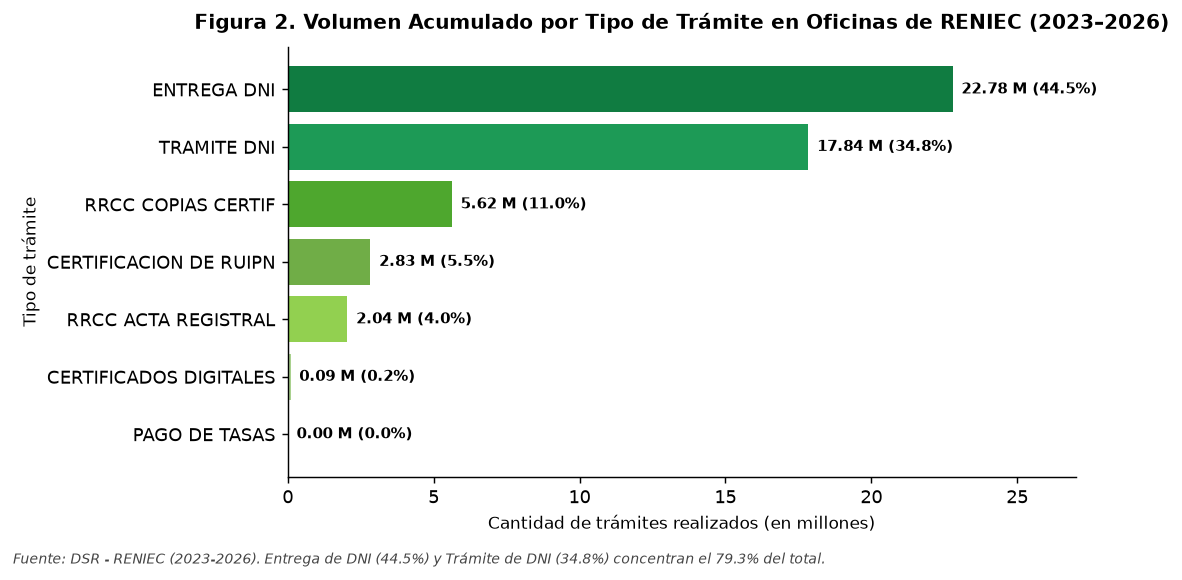

In [9]:
tram_mill = (df_limpio.groupby("TIPO_TRANSACCION")["TRANSACCIONES"].sum().sort_values(ascending=False) / 1e6)

fig, ax = plt.subplots(figsize=(8.5, 4.3))
colors_t = ["#107c41", "#1d9a56", "#4ea72e", "#70ad47", "#92d050", "#a9d18e", "#c5e0b4"]
bars = ax.barh(tram_mill.index[::-1], tram_mill.values[::-1], color=colors_t[::-1])
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.3, bar.get_y() + bar.get_height()/2, f"{w:.2f} M ({w/51.216*100:.1f}%)", va="center", fontsize=8.5, fontweight="bold")
ax.set_xlim(0, 27)
ax.set_title("Figura 2. Volumen Acumulado por Tipo de Trámite en Oficinas de RENIEC (2023–2026)", fontsize=11, fontweight="bold", pad=10)
ax.set_xlabel("Cantidad de trámites realizados (en millones)", fontsize=9.5)
ax.set_ylabel("Tipo de trámite", fontsize=9.5)
plt.figtext(0.01, -0.02, "Fuente: DSR - RENIEC (2023-2026). Entrega de DNI (44.5%) y Trámite de DNI (34.8%) concentran el 79.3% del total.", fontsize=8, style="italic", color="#444444")
plt.tight_layout()
plt.savefig("imagenes/fig2_tipo_tramite.png", bbox_inches="tight", dpi=150)
plt.show()


### 6.3 Figura 3: Distribución Asimétrica del Volumen Mensual y Comparación por Macro-Trámite
Para visualizar honestamente los `88,584` registros sin que la cola extrema (`199,485`) oculte el comportamiento del 90 % de las oficinas, combinamos el histograma en escala logarítmica (marcando la **Mediana = 81** y la **Media = 578.17**) con el diagrama de caja por macro-categoría.


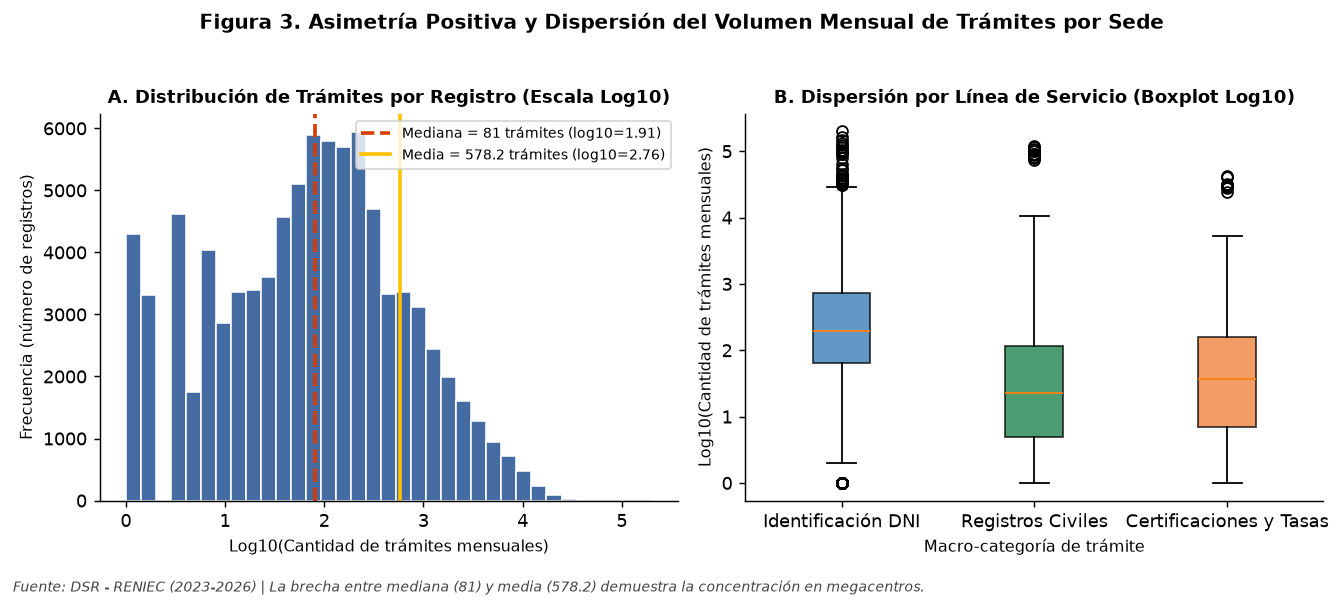

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))

# Panel A: Histograma de LOG10(TRANSACCIONES)
ax1.hist(df_limpio["LOG10_TRANSAC"], bins=35, color="#2b5797", edgecolor="white", alpha=0.88)
ax1.axvline(np.log10(81), color="#d83b01", linestyle="--", linewidth=2, label="Mediana = 81 trámites (log10=1.91)")
ax1.axvline(np.log10(578.17), color="#ffc000", linestyle="-", linewidth=2, label="Media = 578.2 trámites (log10=2.76)")
ax1.set_title("A. Distribución de Trámites por Registro (Escala Log10)", fontsize=10, fontweight="bold")
ax1.set_xlabel("Log10(Cantidad de trámites mensuales)", fontsize=9)
ax1.set_ylabel("Frecuencia (número de registros)", fontsize=9)
ax1.legend(fontsize=8)

# Panel B: Boxplot por Macro-Trámite en escala Log10
grupos = ["IDENTIFICACION DNI", "REGISTROS CIVILES", "CERTIFICACIONES Y TASAS"]
datos_box = [df_limpio[df_limpio["MACRO_TRAMITE"] == g]["LOG10_TRANSAC"] for g in grupos]
bp = ax2.boxplot(datos_box, tick_labels=["Identificación DNI", "Registros Civiles", "Certificaciones y Tasas"], patch_artist=True)
for patch, col in zip(bp["boxes"], ["#2e75b6", "#107c41", "#ed7d31"]):
    patch.set_facecolor(col)
    patch.set_alpha(0.75)
ax2.set_title("B. Dispersión por Línea de Servicio (Boxplot Log10)", fontsize=10, fontweight="bold")
ax2.set_xlabel("Macro-categoría de trámite", fontsize=9)
ax2.set_ylabel("Log10(Cantidad de trámites mensuales)", fontsize=9)

plt.suptitle("Figura 3. Asimetría Positiva y Dispersión del Volumen Mensual de Trámites por Sede", fontsize=11, fontweight="bold", y=1.03)
plt.figtext(0.01, -0.03, "Fuente: DSR - RENIEC (2023-2026) | La brecha entre mediana (81) y media (578.2) demuestra la concentración en megacentros.", fontsize=8, style="italic", color="#444444")
plt.tight_layout()
plt.savefig("imagenes/fig3_distribucion_boxplot.png", bbox_inches="tight", dpi=150)
plt.show()


### 6.4 Figura 4: Evolución Anual y Comportamiento Estacional Mensual (2023–2026) (Responde P3)


/tmp/ipykernel_8582/2725421281.py:26: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


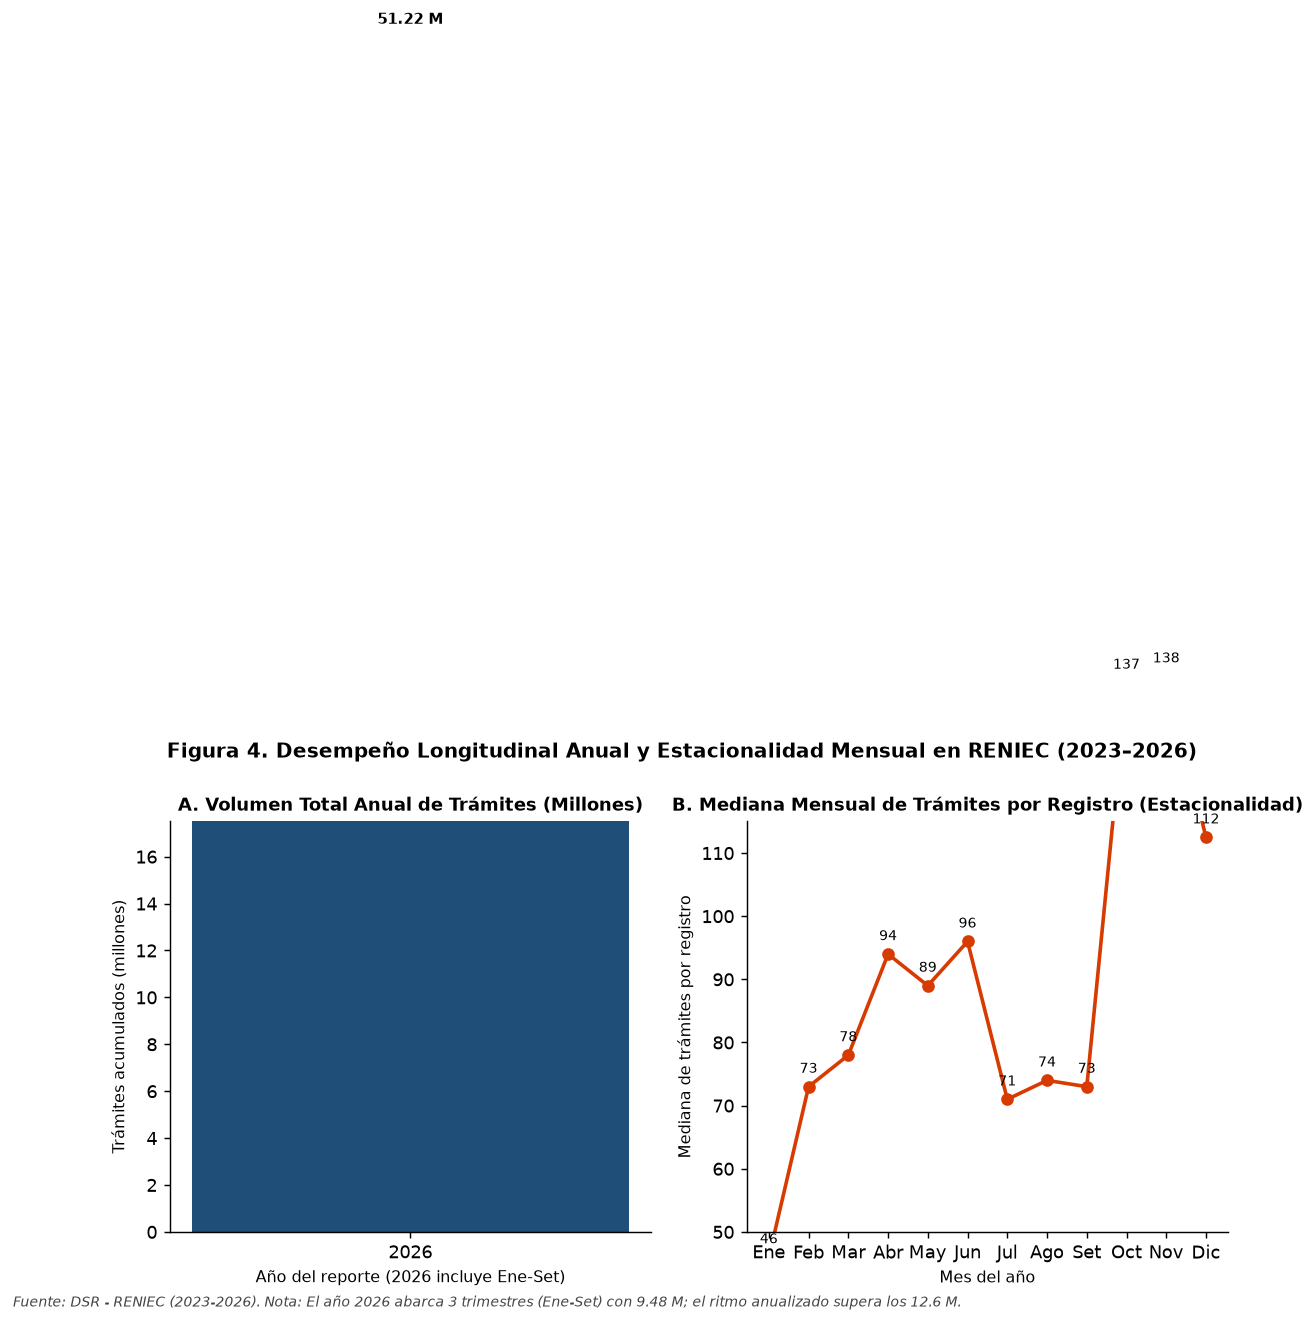

In [11]:
anual = df_limpio.groupby("ANIO")["TRANSACCIONES"].sum() / 1e6
mensual = df_limpio.groupby("MES_NUM")["TRANSACCIONES"].median()
nombres_mes = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Set", "Oct", "Nov", "Dic"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.1))

bars_a = ax1.bar(anual.index.astype(str), anual.values, color=["#1f4e79", "#2e75b6", "#418ab3", "#ed7d31"], width=0.55)
for b in bars_a:
    h = b.get_height()
    ax1.text(b.get_x() + b.get_width()/2, h + 0.3, f"{h:.2f} M", ha="center", fontsize=8.5, fontweight="bold")
ax1.set_ylim(0, 17.5)
ax1.set_title("A. Volumen Total Anual de Trámites (Millones)", fontsize=10, fontweight="bold")
ax1.set_xlabel("Año del reporte (2026 incluye Ene-Set)", fontsize=9)
ax1.set_ylabel("Trámites acumulados (millones)", fontsize=9)

ax2.plot(nombres_mes, mensual.values, marker="o", color="#d83b01", linewidth=2)
for x, y in enumerate(mensual.values):
    ax2.text(x, y + 2.2, f"{int(y)}", ha="center", fontsize=8)
ax2.set_ylim(50, 115)
ax2.set_title("B. Mediana Mensual de Trámites por Registro (Estacionalidad)", fontsize=10, fontweight="bold")
ax2.set_xlabel("Mes del año", fontsize=9)
ax2.set_ylabel("Mediana de trámites por registro", fontsize=9)

plt.suptitle("Figura 4. Desempeño Longitudinal Anual y Estacionalidad Mensual en RENIEC (2023–2026)", fontsize=11, fontweight="bold", y=1.03)
plt.figtext(0.01, -0.03, "Fuente: DSR - RENIEC (2023-2026). Nota: El año 2026 abarca 3 trimestres (Ene-Set) con 9.48 M; el ritmo anualizado supera los 12.6 M.", fontsize=8, style="italic", color="#444444")
plt.tight_layout()
plt.savefig("imagenes/fig4_evolucion_temporal.png", bbox_inches="tight", dpi=150)
plt.show()


### 6.5 Figura 5: Foco Territorial en la Región Puno – Provincias y Oficinas Líderes (Responde P1 Regional)


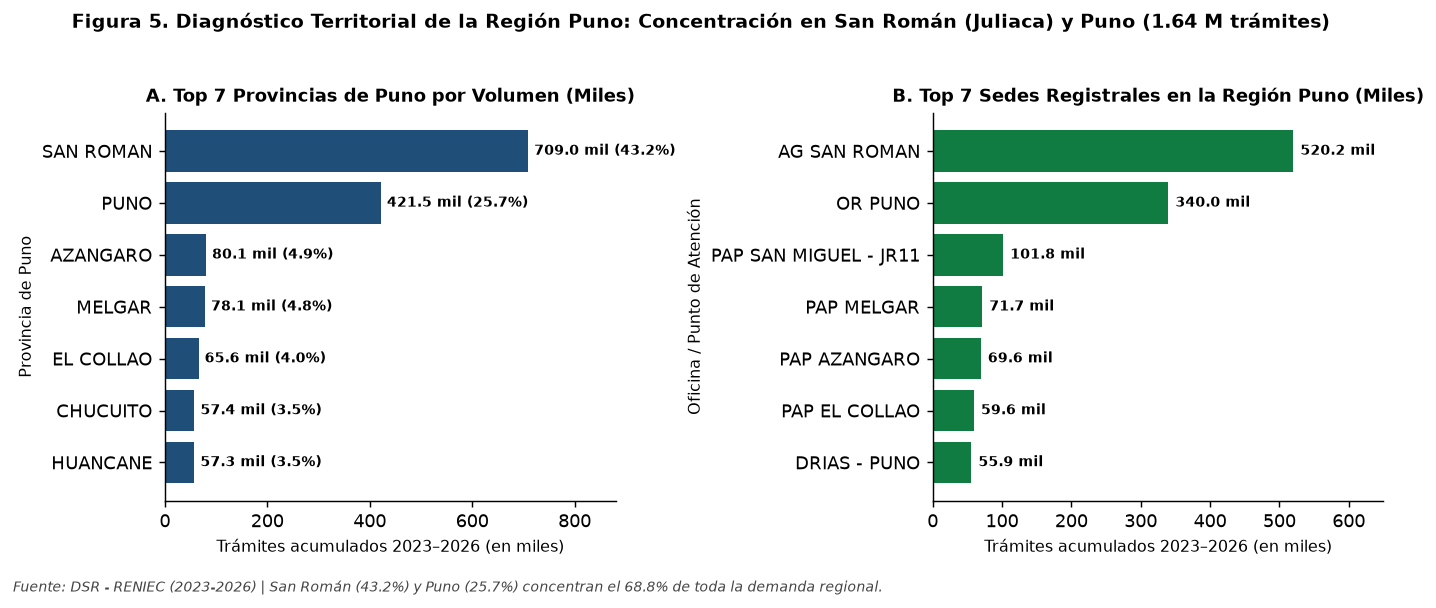

In [12]:
top_prov_puno = df_puno.groupby("PROVINCIA")["TRANSACCIONES"].sum().sort_values(ascending=False).head(7) / 1e3
top_loc_puno = df_puno.groupby("LOCAL")["TRANSACCIONES"].sum().sort_values(ascending=False).head(7) / 1e3

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.2))

b1 = ax1.barh(top_prov_puno.index[::-1], top_prov_puno.values[::-1], color="#1f4e79")
for b in b1:
    w = b.get_width()
    ax1.text(w + 12, b.get_y() + b.get_height()/2, f"{w:,.1f} mil ({w/1642.48*100:.1f}%)", va="center", fontsize=8, fontweight="bold")
ax1.set_xlim(0, 880)
ax1.set_title("A. Top 7 Provincias de Puno por Volumen (Miles)", fontsize=10, fontweight="bold")
ax1.set_xlabel("Trámites acumulados 2023–2026 (en miles)", fontsize=9)
ax1.set_ylabel("Provincia de Puno", fontsize=9)

b2 = ax2.barh(top_loc_puno.index[::-1], top_loc_puno.values[::-1], color="#107c41")
for b in b2:
    w = b.get_width()
    ax2.text(w + 10, b.get_y() + b.get_height()/2, f"{w:,.1f} mil", va="center", fontsize=8, fontweight="bold")
ax2.set_xlim(0, 650)
ax2.set_title("B. Top 7 Sedes Registrales en la Región Puno (Miles)", fontsize=10, fontweight="bold")
ax2.set_xlabel("Trámites acumulados 2023–2026 (en miles)", fontsize=9)
ax2.set_ylabel("Oficina / Punto de Atención", fontsize=9)

plt.suptitle("Figura 5. Diagnóstico Territorial de la Región Puno: Concentración en San Román (Juliaca) y Puno (1.64 M trámites)", fontsize=10.5, fontweight="bold", y=1.03)
plt.figtext(0.01, -0.03, "Fuente: DSR - RENIEC (2023-2026) | San Román (43.2%) y Puno (25.7%) concentran el 68.8% de toda la demanda regional.", fontsize=8, style="italic", color="#444444")
plt.tight_layout()
plt.savefig("imagenes/fig5_zoom_puno.png", bbox_inches="tight", dpi=150)
plt.show()


---
## 7. Detección de Patrones Multivariados: Tablas Dinámicas y Correlación de Spearman (Campo 8 FO1 · Criterio 6)
### 7.1 Tabla Dinámica (`pivot_table`) de Provincias Líderes de Puno vs. Tipo de Trámite


In [13]:
top6_prov = prov_puno.head(6).index
piv_puno = pd.pivot_table(
    df_puno[df_puno["PROVINCIA"].isin(top6_prov)],
    index="PROVINCIA",
    columns="MACRO_TRAMITE",
    values="TRANSACCIONES",
    aggfunc="sum",
    margins=True,
    margins_name="TOTAL"
)
print("Tabla Dinámica (Suma de trámites por Provincia y Línea de Servicio en Puno):")
display(piv_puno.map(lambda x: f"{int(x):,}"))

# Tabla de proporciones por fila (crosstab porcentual)
prop_puno = pd.crosstab(
    df_puno[df_puno["PROVINCIA"].isin(top6_prov)]["PROVINCIA"],
    df_puno[df_puno["PROVINCIA"].isin(top6_prov)]["MACRO_TRAMITE"],
    values=df_puno[df_puno["PROVINCIA"].isin(top6_prov)]["TRANSACCIONES"],
    aggfunc="sum",
    normalize="index"
) * 100
print("Proporción porcentual (%) de cada línea de servicio dentro de las principales provincias de Puno:")
display(prop_puno.round(2))


Tabla Dinámica (Suma de trámites por Provincia y Línea de Servicio en Puno):


MACRO_TRAMITE,CERTIFICACIONES Y TASAS,IDENTIFICACION DNI,REGISTROS CIVILES,TOTAL
PROVINCIA,,,,
AZANGARO,"4,901","70,992","4,241","80,134"
CHUCUITO,"2,369","51,343","3,737","57,449"
EL COLLAO,"2,574","60,754","2,311","65,639"
MELGAR,"6,026","65,912","6,176","78,114"
PUNO,"35,880","339,405","46,229","421,514"
SAN ROMAN,"48,587","609,035","51,376","708,998"
TOTAL,"100,337","1,197,441","114,070","1,411,848"


Proporción porcentual (%) de cada línea de servicio dentro de las principales provincias de Puno:


MACRO_TRAMITE,CERTIFICACIONES Y TASAS,IDENTIFICACION DNI,REGISTROS CIVILES
PROVINCIA,,,
AZANGARO,6.12,88.59,5.29
CHUCUITO,4.12,89.37,6.50
EL COLLAO,3.92,92.56,3.52
MELGAR,7.71,84.38,7.91
PUNO,8.51,80.52,10.97
SAN ROMAN,6.85,85.90,7.25


### 7.2 Análisis de Correlación por Rangos de Spearman ($r_s$) entre Servicios por Oficina (Responde P4)
Justificación de **Spearman ($r_s$)** frente a Pearson ($r$): Como demostramos en la Sección 5, el volumen de trámites por oficina tiene asimetría extrema ($	ext{skew} = 35.84$) y presencia de megacentros, lo que distorsiona la correlación lineal de Pearson. El coeficiente de **Spearman ($r_s$)** evalúa relaciones monótonas sobre los rangos ordenados de cada agencia, siendo robusto a valores extremos.


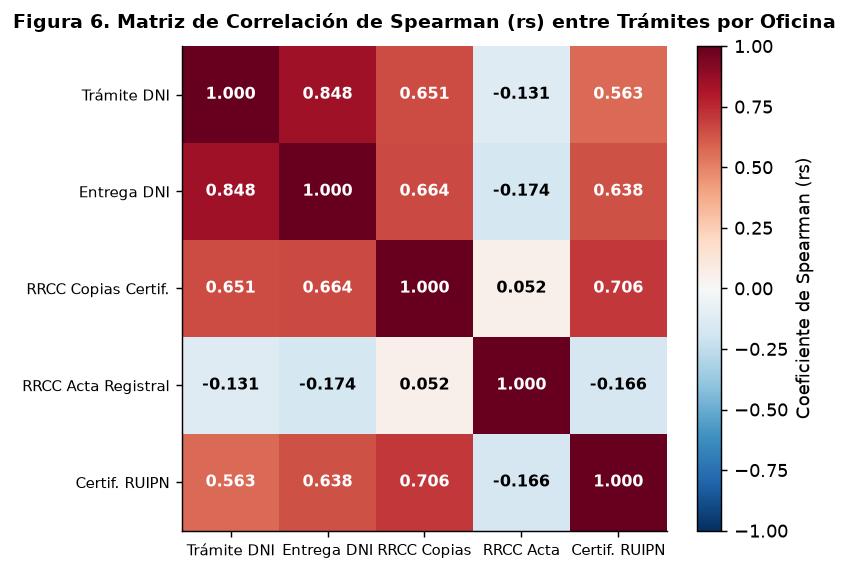

TIPO_TRANSACCION,TRAMITE DNI,ENTREGA DNI,RRCC COPIAS CERTIF,RRCC ACTA REGISTRAL,CERTIFICACION DE RUIPN
TIPO_TRANSACCION,,,,,
TRAMITE DNI,1.000,0.848,0.651,-0.131,0.563
ENTREGA DNI,0.848,1.000,0.664,-0.174,0.638
RRCC COPIAS CERTIF,0.651,0.664,1.000,0.052,0.706
RRCC ACTA REGISTRAL,-0.131,-0.174,0.052,1.000,-0.166
CERTIFICACION DE RUIPN,0.563,0.638,0.706,-0.166,1.000


In [14]:
# Matriz de volumen acumulado por oficina y tipo de trámite (n = 2,316 sedes)
matriz_oficinas = df_limpio.pivot_table(
    index=["DEPARTAMENTO", "LOCAL"],
    columns="TIPO_TRANSACCION",
    values="TRANSACCIONES",
    aggfunc="sum",
    fill_value=0
)
cols_clave = ["TRAMITE DNI", "ENTREGA DNI", "RRCC COPIAS CERTIF", "RRCC ACTA REGISTRAL", "CERTIFICACION DE RUIPN"]
corr_spearman = matriz_oficinas[cols_clave].corr(method="spearman").round(3)

fig, ax = plt.subplots(figsize=(6.8, 4.5))
im = ax.imshow(corr_spearman.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols_clave)))
ax.set_yticks(range(len(cols_clave)))
ax.set_xticklabels(["Trámite DNI", "Entrega DNI", "RRCC Copias", "RRCC Acta", "Certif. RUIPN"], fontsize=8.5)
ax.set_yticklabels(["Trámite DNI", "Entrega DNI", "RRCC Copias Certif.", "RRCC Acta Registral", "Certif. RUIPN"], fontsize=8.5)
for i in range(len(cols_clave)):
    for j in range(len(cols_clave)):
        val = corr_spearman.values[i, j]
        ax.text(j, i, f"{val:.3f}", ha="center", va="center", color="white" if abs(val) > 0.5 else "black", fontweight="bold", fontsize=9)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Coeficiente de Spearman (rs)")
ax.set_title("Figura 6. Matriz de Correlación de Spearman (rs) entre Trámites por Oficina", fontsize=10.5, fontweight="bold", pad=10)
plt.tight_layout()
plt.savefig("imagenes/fig6_correlacion_spearman.png", bbox_inches="tight", dpi=150)
plt.show()

corr_spearman


### 7.3 Interpretación de Patrones y Distinción entre Correlación y Causalidad
1. **Patrón 1 – Acoplamiento operativo Trámite DNI ↔ Entrega DNI ($r_s = +0.848$):** Existe una asociación positiva muy fuerte entre el rango de solicitudes de DNI y el rango de entregas de DNI en cada oficina. *Advertencia de no-causalidad:* Esto no significa que abrir más ventanillas de entrega cause por sí mismo más solicitudes; ambas variables están gobernadas por un **factor confusor externo**: el tamaño demográfico de la jurisdicción y la categoría de la agencia.
2. **Patrón 2 – Especialización diferenciada en Actas Registrales ($r_s = -0.131$ con Trámite DNI):** La correlación levemente negativa entre `TRAMITE DNI` y `RRCC ACTA REGISTRAL` revela la división funcional de la red de RENIEC: cientos de Oficinas Registrales Auxiliares (ORAF en hospitales y municipios rurales) registran exclusivamente nacimientos y defunciones (`RRCC ACTA REGISTRAL`) sin emitir DNI, mientras las agencias urbanas concentran la identificación.
3. **Patrón 3 – Concentración bipolar en la Región Puno (68.83 % en 2 de 13 provincias):** En Puno, **San Román (`708,998` trámites; `43.17 %`)** y **Puno (`421,514` trámites; `25.66 %`)** absorben más de dos tercios de toda la carga departamental, y la **Agencia San Román (Juliaca)** más el **PAP San Miguel** (`621,958` trámites sumados) superan ampliamente a la propia sede de la capital departamental (`OR PUNO` con `339,959` trámites).


---
## 8. Conclusiones para la Toma de Decisiones y Limitaciones del Estudio (Campo 9 FO1 · Criterio 6)
### 8.1 Tres hallazgos estructurados con recomendaciones accionables


In [15]:
hallazgos_decisiones = pd.DataFrame([
    {
        "N°": 1,
        "Hallazgo principal": "Hiperconcentración en Lima (38.8% nacional) y en el eje San Román–Puno (68.8% regional)",
        "Evidencia cuantitativa y gráfica": "Lima suma 19.88 M de trámites (Fig. 1). En Puno (1.64 M), San Román lidera con 708,998 (43.2%) y Puno con 421,514 (25.7%) (Fig. 5). El P90 nacional es 1,214 trámites/mes frente a una mediana de 81.",
        "¿Prueba causalidad?": "No. La alta asociación entre sede urbana y volumen responde a la densidad poblacional y migración comercial (ej. Juliaca como nodo comercial del sur), no a una ineficiencia de las sedes rurales.",
        "Decisión recomendada para RENIEC": "Redistribuir personal y ventanillas móviles hacia la Agencia San Román y el PAP San Miguel en Juliaca, elevando su categoría operativa, e implementar tótems de entrega rápida en sedes que superen el P90 (>1,214 trámites/mes)."
    },
    {
        "N°": 2,
        "Hallazgo principal": "Predominio absoluto de la cadena de DNI (79.3% nacional y 85.6% en la región Puno)",
        "Evidencia cuantitativa y gráfica": "Entrega de DNI (22.78 M, 44.5%) y Trámite de DNI (17.84 M, 34.8%) suman 40.63 M de trámites (Fig. 2) y exhiben correlación de Spearman rs = +0.848 (Fig. 6). En Puno, Entrega DNI llega al 50.04%.",
        "¿Prueba causalidad?": "No es causalidad directa aislada: cada trámite de DNI genera posteriormente una entrega física, mediada por los plazos logísticos de impresión en Lima y envío a provincias.",
        "Decisión recomendada para RENIEC": "Separar físicamente las ventanillas de 'Solo Entrega de DNI' (operación rápida de <2 min) de las ventanillas de 'Captura/Trámite DNI' en OR Puno y AG San Román, y ampliar el uso de DNI Electrónico y recojo automatizado."
    },
    {
        "N°": 3,
        "Hallazgo principal": "Estabilidad interanual (>12.5 M/año) con picos estacionales en verano (Ene–Feb) y agosto",
        "Evidencia cuantitativa y gráfica": "El flujo anual se mantiene entre 12.6 M y 14.7 M (Fig. 4A) y la mediana mensual sube a 98-100 trámites en enero, febrero y agosto frente a 67 en diciembre (Fig. 4B).",
        "¿Prueba causalidad?": "No prueba causalidad del mes calendario por sí solo; los picos coinciden con factores externos como vacaciones escolares, matrículas y campañas de renovación preelectoral.",
        "Decisión recomendada para RENIEC": "Programar campañas itinerantes y contratación temporal de registradores en los meses pico (enero–febrero y julio–agosto) y programar mantenimientos de sistemas o vacaciones del personal en meses valle (noviembre–diciembre)."
    }
])
hallazgos_decisiones


,N°,Hallazgo principal,Evidencia cuantitativa y gráfica,¿Prueba causalidad?,Decisión recomendada para RENIEC
0,1,Hiperconcentración en Lima (38.8% nacional) y ...,Lima suma 19.88 M de trámites (Fig. 1). En Pun...,No. La alta asociación entre sede urbana y vol...,Redistribuir personal y ventanillas móviles ha...
1,2,Predominio absoluto de la cadena de DNI (79.3%...,"Entrega de DNI (22.78 M, 44.5%) y Trámite de D...",No es causalidad directa aislada: cada trámite...,Separar físicamente las ventanillas de 'Solo E...
2,3,Estabilidad interanual (>12.5 M/año) con picos...,El flujo anual se mantiene entre 12.6 M y 14.7...,No prueba causalidad del mes calendario por sí...,Programar campañas itinerantes y contratación ...


### 8.2 Limitaciones técnicas y metodológicas del estudio
1. **Omisión de la variable `DISTRITO` en los reportes oficiales 2025–2026 (Mecanismo MNAR):** La DSR de RENIEC dejó de incluir la columna `DISTRITO` en los archivos de 2025 y 2026 (`22,193` filas válidas etiquetadas como `'NO REGISTRADO'`). Por ello, el análisis territorial longitudinal 2023–2026 es 100 % exacto a nivel de **Departamento, Provincia y Oficina (`LOCAL`)**, pero no debe desagregarse por distrito en el bienio 2025–2026 sin cruzar un catálogo maestro de ubigeos.
2. **Corte parcial del año 2026:** Los datos disponibles de 2026 cubren de enero a septiembre (3 trimestres, `9.48` millones de trámites). Para comparaciones de cierre anual debe considerarse su proyección anualizada (`~12.64` millones).
3. **Datos agregados sin tiempos individuales de espera:** El dataset reporta volúmenes mensuales por oficina y tipo de trámite, pero no registra tiempos de espera en cola por ciudadano ni encuestas de satisfacción, lo cual constituiría el siguiente paso para cruzar carga operativa con calidad de servicio.
